# 09_05 Anomaly Detection: z-scores, Mahalanobis Distance and Robust Statistics

**Learning objectives**
- Flag anomalies with the **z-score**, the **robust z-score** (median and MAD) and the **IQR rule**, and compute their **false-alarm rates** under normal and heavy-tailed data.
- Explain the **Mahalanobis distance**, show that $D^2\sim\chi^2_p$ for Gaussian data, and set a **statistical threshold** from a false-alarm budget.
- Understand **masking** (outliers hiding themselves by inflating the covariance) and fix it with a **robust covariance** (reweighted minimum covariance determinant, written from scratch).
- Score anomalies from a fitted **density** (09_04) and control false alarms when **monitoring many metrics** at once (multiple testing).

**Prerequisites:** [03_01 Multivariate normal](../../module_03_multivariate/notebooks/03_01_multivariate_normal.ipynb), [02_08 Chi-square, t and F](../../module_02_continuous/notebooks/02_08_student_t_chi_square_f.ipynb), [06_06 Multiple testing](../../module_06_inference/notebooks/06_06_multiple_testing.ipynb), [09_04 Density estimation](09_04_density_estimation_kde_gmm_em.ipynb).

## 1. Setup

All imports in one cell; the generator is seeded so every run gives the same numbers.

In [1]:
import sys
sys.path.append("../..")  # repo root, so common.style can be imported
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import plotly.graph_objects as go
from scipy import stats
from common.style import apply_style, MAIN, SIM, HIGHLIGHT, NEUTRAL, COLORS

apply_style()
rng = np.random.default_rng(42)  # fixed seed so every run gives the same numbers

## 2. Prerequisite recap
For $X\sim N(\mu,\sigma^2)$, $Z=(X-\mu)/\sigma$ is standard normal and $P(|Z|>3)=0.0027$. For a $p$-dimensional Gaussian $N(\mu,\Sigma)$ the squared Mahalanobis distance $(x-\mu)^\top\Sigma^{-1}(x-\mu)$ has a $\chi^2_p$ distribution (03_01). The mean and standard deviation are sensitive to outliers; the median and the median absolute deviation (MAD) are not.

## 3. Intuition and story
An anomaly is an observation that the usual process would almost never produce. "Almost never" needs a model of "usual": for one metric (latency) it is a mean and spread; for several related metrics (transaction amount, hour, distance from home) it is a **cloud with a shape**. A purchase of 900 dollars at 3 am in another country may be unremarkable on each coordinate separately but is far outside the cloud *as a whole*. The Mahalanobis distance measures how many "standard deviations" a point is from the centre **taking the shape of the cloud into account**, and under a Gaussian model that distance has a known distribution, so a threshold can be set from the false-alarm rate you can afford.

Two practical dangers: the anomalies you want to find also **contaminate the estimate of "usual"** (they inflate the spread so they look normal: *masking*), and with hundreds of metrics even a rare 3-sigma rule fires **every day by chance**.

## 4. Formal definitions

| Score | Definition | Flag when |
|---|---|---|
| **z-score** | $z=(x-\bar x)/s$ | $|z|>c$ ($c=3$: 0.27 % false alarms if normal) |
| **Robust z-score** | $z_R=0.6745\,(x-\mathrm{med})/\mathrm{MAD}$, $\mathrm{MAD}=\mathrm{med}|x_i-\mathrm{med}|$ | $|z_R|>3.5$ |
| **IQR rule** | $x<Q_1-1.5\,\mathrm{IQR}$ or $x>Q_3+1.5\,\mathrm{IQR}$ | (Tukey fences) |
| **Mahalanobis** | $D^2(x)=(x-\hat\mu)^\top\hat\Sigma^{-1}(x-\hat\mu)$ | $D^2>\chi^2_{p,1-\alpha}$ |
| **Density score** | $-\ln\hat f(x)$ from a KDE or mixture (09_04) | score above the $1-\alpha$ quantile of normal data |
| **MCD** | mean and covariance of the $h$ points (typically $h=0.75n$) with smallest covariance determinant | robust $D^2$ |

**Exact result:** for $n$ Gaussian points with the sample mean and covariance plugged in, $\dfrac{n}{(n-1)^2}D_i^2\sim\mathrm{Beta}\!\big(\tfrac p2,\tfrac{n-p-1}2\big)$; for large $n$ this is $\chi^2_p/n$. The MAD is scaled by 0.6745 so that $z_R$ matches $z$ for normal data.

## 5. Derivations

### 5.1 The false-alarm rate of a $c$-sigma rule
For a standard normal, $P(|Z|>c)=2(1-\Phi(c))$: 4.6 % for $c=2$, 0.27 % for $c=3$, $6\times10^{-5}$ for $c=4$. For a heavy-tailed $t_3$ distribution rescaled to unit variance the same rule fires with probability $2P(t_3>3\sqrt3)=1.4$ %. **In plain words.** The rule that fires once in 370 normal points fires once in 72 points of heavy-tailed data (five times as often); the threshold must be chosen for the distribution you actually have.

### 5.2 $D^2$ is a sum of $p$ squared independent normals
Write $\Sigma=LL^\top$ and $Z=L^{-1}(X-\mu)$; then $Z\sim N(0,I_p)$ and $D^2=Z^\top Z=\sum_jZ_j^2\sim\chi^2_p$ (02_08). **In plain words.** Mahalanobis distance first untangles and rescales the coordinates (whitening) so that the cloud becomes round with unit spread, and then takes the ordinary squared distance; summing $p$ squared standard normals gives a chi-square with $p$ degrees of freedom, whose 99.9 % point is 13.8 for $p=2$, 20.5 for $p=5$ and 29.6 for $p=10$.

### 5.3 Why Euclidean distance fails
If two features are strongly correlated ($\rho=0.9$), the cloud is a thin ellipse. A point that is perpendicular to the ellipse at modest Euclidean distance breaks the correlation and is very unusual, while a point far along the major axis is perfectly ordinary. $D^2$ divides by the *direction-specific* spread: along the minor axis the spread is $\sigma\sqrt{1-\rho}$ and along the major axis $\sigma\sqrt{1+\rho}$, a ratio of $\sqrt{19}=4.4$. **In plain words.** Distance should be measured in units of how much the data normally vary in that direction.

### 5.4 Masking and the breakdown point
The sample mean has breakdown point 0 (one huge outlier moves it anywhere) and the median 50 %. In the multivariate case a cluster of outliers inflates $\hat\Sigma$ along its direction; the anomalies' own $D^2$ then shrinks (masking). The MCD uses only the $h$ best-fitting points, so contamination up to $n-h$ points (25 % for $h=0.75n$) cannot move it; the C-step (compute $D^2$, keep the $h$ smallest, recompute) never increases the determinant. **In plain words.** Estimate "normal" from the most normal-looking 75 % of the data and then judge everyone, including the discarded 25 %.

### 5.5 Monitoring many metrics
With $m$ independent metrics each tested at level $\alpha$ the expected number of false alarms is $m\alpha$ and the chance of at least one is $1-(1-\alpha)^m$. Bonferroni uses $\alpha/m$; Benjamini-Hochberg controls the false discovery rate (06_06). **In plain words.** With 500 dashboard metrics a 3-sigma rule produces about 1.35 false alarms every day; the alerting rule has to account for the number of looks.

## 6. Properties and relationships
- **Unsupervised:** only the "normal" distribution is modelled; anomalies are whatever it finds unlikely. Labelled anomalies, when available, are used for evaluation (precision, recall, AUC), not for fitting.
- **Threshold = false-alarm budget:** a $1-\alpha$ quantile of the score on normal data fixes the false-alarm rate (at the base rate of anomalies the *precision* can still be poor).
- **Gaussian assumption:** skewed or multimodal normal behaviour needs a transformation (log) or a flexible density (09_04 GMM/KDE).
- **Base rate:** if 1 in 1,000 points is anomalous, even a detector with 1 % false alarms has precision under 10 % (00_05 Bayes' rule).
- **Link to ML and AI:** fraud and intrusion detection, predictive maintenance, data validation and **drift monitoring** (08_02), out-of-distribution detection with embeddings (Mahalanobis distance in feature space), and the reconstruction-error detectors of autoencoders.

## 7. Helpers

Z-scores, robust z-scores, Mahalanobis distance and a from-scratch MCD (C-steps with random starts and the consistency correction).

In [2]:
from scipy.stats import rankdata
def zs(x): return (x - x.mean()) / x.std(ddof=1)
def rz(x): m = np.median(x); mad = np.median(np.abs(x - m)); return 0.6745 * (x - m) / mad
def d2(X, mu, S): Z = X - mu; return np.einsum("ij,jk,ik->i", Z, np.linalg.inv(S), Z)
def mcd(X, h=0.75, starts=60, seed=0, csteps=30):
    n, p = X.shape; hh = int(h * n); g = np.random.default_rng(seed); best = (np.inf, None, None)
    med = np.median(X, axis=0); S_med = np.diag((1.4826 * np.median(np.abs(X - med), axis=0)) ** 2)
    for s_ in range(starts):
        if s_ == 0: mu, S = med, S_med
        else: idx = g.choice(n, p + 1 + s_ % 5, replace=False); mu, S = X[idx].mean(axis=0), np.cov(X[idx].T) + 1e-6 * np.eye(p)
        for _ in range(csteps):
            d = d2(X, mu, S); keep = np.argsort(d)[:hh]; mu, S = X[keep].mean(axis=0), np.cov(X[keep].T) + 1e-9 * np.eye(p)
        det = np.linalg.det(S)
        if det < best[0]: best = (det, mu, S)
    _, mu, S = best; q = hh / n; S = S * q / stats.chi2.cdf(stats.chi2.ppf(q, p), p + 2)
    keep = d2(X, mu, S) <= stats.chi2.ppf(0.975, p); q2 = 0.975; return X[keep].mean(axis=0), np.cov(X[keep].T) * q2 / stats.chi2.cdf(stats.chi2.ppf(q2, p), p + 2)   # reweighting step
def auc(score, y): r = rankdata(score); n1 = y.sum(); n0 = len(y) - n1; return (r[y == 1].sum() - n1 * (n1 + 1) / 2) / (n1 * n0)
g = np.random.default_rng(0); C = [[4, 3], [3, 4]]; Xn = g.multivariate_normal([0, 0], C, 20_000); mu_r, S_r = mcd(Xn[:2000], seed=1)
print("MCD of clean Gaussian data (true covariance [[4,3],[3,4]]):", S_r.round(2).tolist(), "| plain covariance:", np.cov(Xn[:2000].T).round(2).tolist())
dd = d2(Xn, Xn.mean(axis=0), np.cov(Xn.T)); print("share of clean points with D2 > chi2(2) 99.9% point:", np.mean(dd > stats.chi2.ppf(0.999, 2)).round(5), "(nominal 0.001)")
assert np.abs(S_r - np.array(C)).max() < 0.5 and abs(np.mean(dd > stats.chi2.ppf(0.999, 2)) - 0.001) < 0.0006 and abs(2 * stats.norm.sf(3) - 0.0027) < 1e-4

MCD of clean Gaussian data (true covariance [[4,3],[3,4]]): [[4.08, 3.11], [3.11, 4.18]] | plain covariance: [[3.92, 3.02], [3.02, 4.1]]
share of clean points with D2 > chi2(2) 99.9% point: 0.00125 (nominal 0.001)


## 8. 2D visuals

### 8.1 How often does a $c$-sigma rule fire?
The share of points flagged by $|z|>c$ for normal data and for heavy-tailed $t_3$ data (scaled to unit variance), against the normal-theory value. A rule calibrated on normal data fires several times too often on heavy tails.

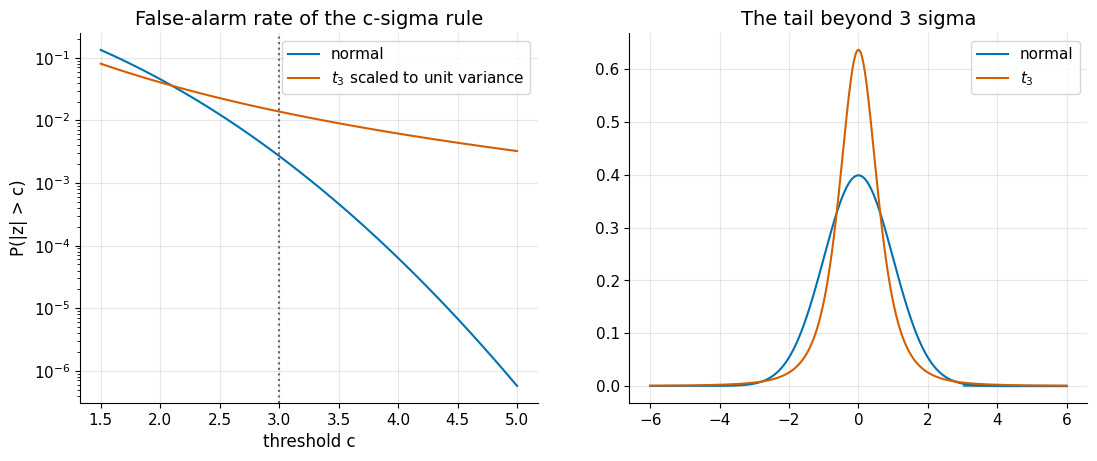

P(|z| > 3): normal 0.00270 | t3 scaled 0.01385 | ratio 5.1


In [3]:
cs = np.linspace(1.5, 5, 60); tt = stats.t(3, scale=1 / np.sqrt(3)); fig, axes = plt.subplots(1, 2, figsize=(13, 4.8)); axes[0].semilogy(cs, 2 * stats.norm.sf(cs), color=MAIN, label="normal"); axes[0].semilogy(cs, 2 * tt.sf(cs), color=HIGHLIGHT, label="$t_3$ scaled to unit variance"); axes[0].axvline(3, color=NEUTRAL, linestyle=":"); axes[0].legend(); axes[0].set_xlabel("threshold c"); axes[0].set_ylabel("P(|z| > c)"); axes[0].set_title("False-alarm rate of the c-sigma rule")
xg = np.linspace(-6, 6, 600); axes[1].plot(xg, stats.norm.pdf(xg), color=MAIN, label="normal"); axes[1].plot(xg, tt.pdf(xg), color=HIGHLIGHT, label="$t_3$"); axes[1].fill_between(xg[xg > 3], tt.pdf(xg[xg > 3]), color=HIGHLIGHT, alpha=0.4); axes[1].fill_between(xg[xg > 3], stats.norm.pdf(xg[xg > 3]), color=MAIN, alpha=0.6); axes[1].set_title("The tail beyond 3 sigma"); axes[1].legend()
plt.show(); print(f"P(|z| > 3): normal {2 * stats.norm.sf(3):.5f} | t3 scaled {2 * tt.sf(3):.5f} | ratio {2 * tt.sf(3) / (2 * stats.norm.sf(3)):.1f}"); assert 2 * tt.sf(3) > 3 * 2 * stats.norm.sf(3)

### 8.2 Euclidean against Mahalanobis
A correlated cloud ($\rho=0.75$). Points A and B are at the same Euclidean distance from the centre, but B breaks the correlation. The 99.9 % ellipse is the Mahalanobis threshold; circles are Euclidean distance.

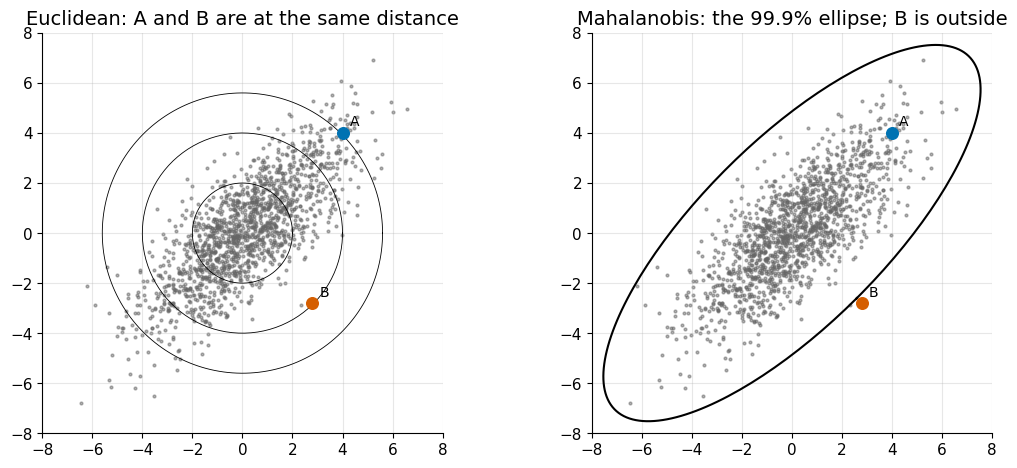

Euclidean distances: 5.66 3.96 | D2 of A and B: [4.3] [16.] | chi2(2) 99.9% point: 13.82


In [4]:
g = np.random.default_rng(2); Xc = g.multivariate_normal([0, 0], C, 1500); mu_c, S_c = Xc.mean(axis=0), np.cov(Xc.T); A = np.array([[4.0, 4.0]]); Bp = np.array([[2.8, -2.8]]); fig, axes = plt.subplots(1, 2, figsize=(13, 5.2))
ang = np.linspace(0, 2 * np.pi, 200); w, v = np.linalg.eigh(S_c); ell = lambda r: (v @ (np.sqrt(w)[:, None] * r * np.array([np.cos(ang), np.sin(ang)]))).T
for ax in axes: ax.scatter(Xc[:, 0], Xc[:, 1], s=4, color=NEUTRAL, alpha=0.5); ax.scatter(*A.T, color=MAIN, s=70, zorder=3); ax.scatter(*Bp.T, color=HIGHLIGHT, s=70, zorder=3); ax.annotate("A", A[0], xytext=(5, 5), textcoords="offset points"); ax.annotate("B", Bp[0], xytext=(5, 5), textcoords="offset points"); ax.set_aspect("equal"); ax.set_xlim(-8, 8); ax.set_ylim(-8, 8)
for r in (2, 4, 5.6): axes[0].plot(r * np.cos(ang), r * np.sin(ang), color="black", linewidth=0.6)
axes[0].set_title("Euclidean: A and B are at the same distance"); e = ell(np.sqrt(stats.chi2.ppf(0.999, 2))); axes[1].plot(e[:, 0], e[:, 1], color="black"); axes[1].set_title("Mahalanobis: the 99.9% ellipse; B is outside")
plt.show(); print("Euclidean distances:", np.linalg.norm(A).round(2), np.linalg.norm(Bp).round(2), "| D2 of A and B:", d2(A, mu_c, S_c).round(1), d2(Bp, mu_c, S_c).round(1), "| chi2(2) 99.9% point:", stats.chi2.ppf(0.999, 2).round(2)); assert d2(A, mu_c, S_c)[0] < stats.chi2.ppf(0.999, 2) < d2(Bp, mu_c, S_c)[0]

### 8.3 $D^2$ is chi-square distributed
The histogram of squared Mahalanobis distances of Gaussian data against the $\chi^2_p$ density for $p=2,5,10$, and the 99.9 % cut-offs.

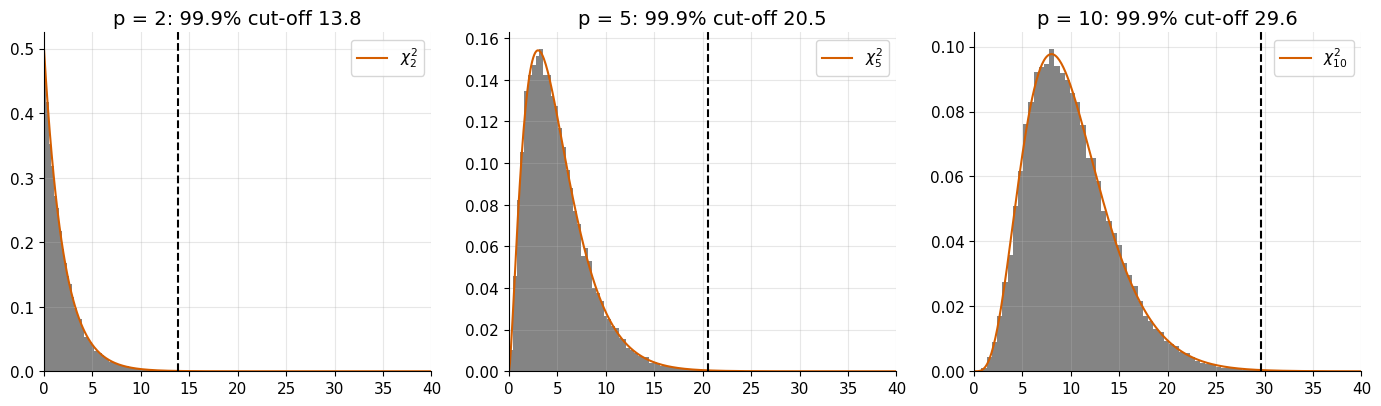

{2: (np.float64(0.001), np.float64(0.0048)), 5: (np.float64(0.00097), np.float64(0.0039)), 10: (np.float64(0.0009), np.float64(0.0036))}


In [5]:
fig, axes = plt.subplots(1, 3, figsize=(17, 4.4)); g = np.random.default_rng(3); cuts = {}
for ax, p in zip(axes, (2, 5, 10)):
    A_ = g.normal(size=(p, p)); S_ = A_ @ A_.T + np.eye(p); Xp = g.multivariate_normal(np.zeros(p), S_, 30_000); dp = d2(Xp, Xp.mean(axis=0), np.cov(Xp.T)); xg = np.linspace(0, 40, 400); ax.hist(dp, bins=80, density=True, color=NEUTRAL, alpha=0.8); ax.plot(xg, stats.chi2.pdf(xg, p), color=HIGHLIGHT, label=f"$\\chi^2_{{{p}}}$"); ax.axvline(stats.chi2.ppf(0.999, p), color="black", linestyle="--"); ax.legend(); ax.set_xlim(0, 40); ax.set_title(f"p = {p}: 99.9% cut-off {stats.chi2.ppf(0.999, p):.1f}"); cuts[p] = (np.mean(dp > stats.chi2.ppf(0.999, p)), stats.kstest(dp, "chi2", args=(p,)).statistic)
plt.show(); print({p: (round(a, 5), round(b, 4)) for p, (a, b) in cuts.items()}); assert all(abs(a - 0.001) < 0.0007 and b < 0.02 for a, b in cuts.values())

## 9. 3D visuals

### 9.1 Static: the anomaly score surface of a bivariate normal
The score $D^2(x)$ is a bowl (a paraboloid) elongated along the correlation axis; the plane at $\chi^2_{2,0.999}=13.8$ cuts out the region of "normal" points. The right panel shows the corresponding density.

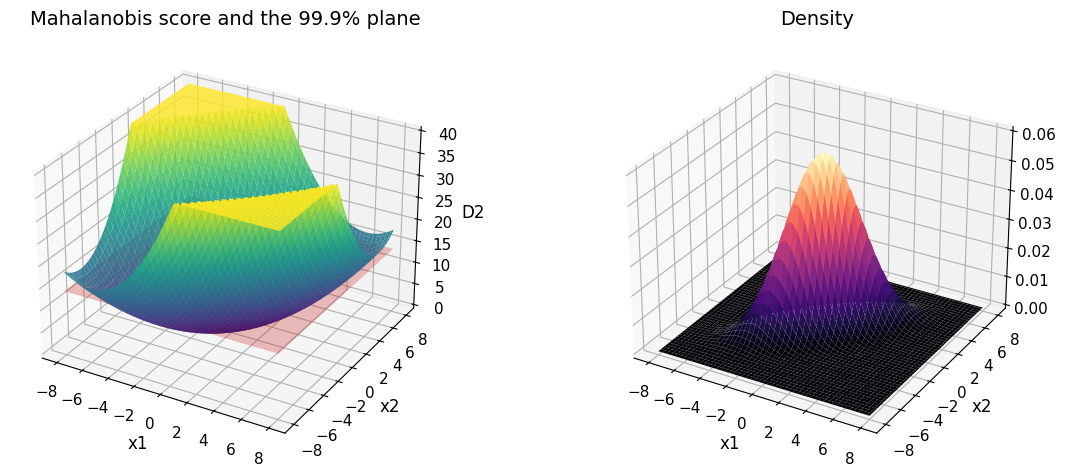

share of the plotted square with D2 below the cut-off: 0.441


In [6]:
gx, gy = np.meshgrid(np.linspace(-8, 8, 100), np.linspace(-8, 8, 100)); P_ = np.column_stack([gx.ravel(), gy.ravel()]); D2g = d2(P_, np.zeros(2), np.array(C)).reshape(gx.shape); dens = stats.multivariate_normal([0, 0], C).pdf(P_).reshape(gx.shape)
fig = plt.figure(figsize=(14, 5.6)); ax = fig.add_subplot(1, 2, 1, projection="3d"); ax.plot_surface(gx, gy, np.minimum(D2g, 40), cmap="viridis", edgecolor="none", alpha=0.9); ax.plot_surface(gx, gy, np.full_like(gx, stats.chi2.ppf(0.999, 2)), color="red", alpha=0.25); ax.set_xlabel("x1"); ax.set_ylabel("x2"); ax.set_zlabel("D2"); ax.set_title("Mahalanobis score and the 99.9% plane"); ax.view_init(elev=28, azim=-60)
ax = fig.add_subplot(1, 2, 2, projection="3d"); ax.plot_surface(gx, gy, dens, cmap="magma", edgecolor="none"); ax.set_title("Density"); ax.set_xlabel("x1"); ax.set_ylabel("x2"); ax.view_init(elev=28, azim=-60)
plt.show(); inside = np.mean(D2g <= stats.chi2.ppf(0.999, 2)); print("share of the plotted square with D2 below the cut-off:", inside.round(3)); assert D2g.min() < 0.05

### 9.2 Interactive Plotly version of 9.1

In [7]:
fig = go.Figure([go.Surface(x=gx[0], y=gy[:, 0], z=np.minimum(D2g, 40), colorscale="Viridis"), go.Surface(x=gx[0], y=gy[:, 0], z=np.full_like(gx, stats.chi2.ppf(0.999, 2)), showscale=False, opacity=0.3, colorscale=[[0, "red"], [1, "red"]])]); fig.update_layout(title="D2 and the 99.9% plane", width=760, height=560, scene=dict(xaxis_title="x1", yaxis_title="x2", zaxis_title="D2")); fig.show()

### 9.3 Static: the cut-off against dimension and false-alarm rate
The chi-square cut-off $\chi^2_{p,1-\alpha}$ grows with the dimension $p$: more coordinates, more room for a large distance by chance. Using the 2D cut-off in 10 dimensions would flag far too many points.

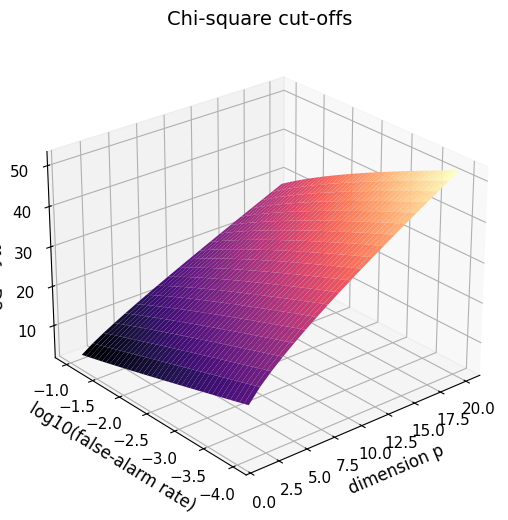

cut-offs for alpha = 0.001: {1: 10.8, 2: 13.8, 5: 20.5, 10: 29.6, 20: 45.3} | false-alarm rate of the p = 2 cut-off in p = 10: 0.182


In [8]:
pg, ag = np.meshgrid(np.arange(1, 21), np.logspace(-4, -1, 40)); CUT = stats.chi2.ppf(1 - ag, pg)
fig = plt.figure(figsize=(8.8, 6.2)); ax = fig.add_subplot(projection="3d"); ax.plot_surface(pg, np.log10(ag), CUT, cmap="magma", edgecolor="none"); ax.set_xlabel("dimension p"); ax.set_ylabel("log10(false-alarm rate)"); ax.set_zlabel("cut-off for D2"); ax.set_title("Chi-square cut-offs"); ax.view_init(elev=26, azim=-130)
plt.show(); print("cut-offs for alpha = 0.001:", {p: round(float(stats.chi2.ppf(0.999, p)), 1) for p in (1, 2, 5, 10, 20)}, "| false-alarm rate of the p = 2 cut-off in p = 10:", round(float(stats.chi2.sf(stats.chi2.ppf(0.999, 2), 10)), 3)); assert abs(stats.chi2.ppf(0.999, 2) - 13.8155) < 1e-3 and stats.chi2.sf(stats.chi2.ppf(0.999, 2), 10) > 0.1

## 10. Simulation vs theory

### 10.1 The exact Beta law of $D^2$ with estimated parameters
For $n=50$ points in $p=3$ dimensions the plug-in $D^2$ is not exactly $\chi^2_3$ (the sample mean and covariance are fitted to the same points): $\frac n{(n-1)^2}D^2\sim\mathrm{Beta}(p/2,(n-p-1)/2)$. Simulate 4,000 datasets and compare the false-alarm rate of the $\chi^2$ and the Beta cut-offs at the 1 % level.

In [9]:
g = np.random.default_rng(5); n, p = 50, 3; vals = []
for _ in range(4000): X_ = g.normal(size=(n, p)); vals.append(d2(X_, X_.mean(axis=0), np.cov(X_.T)))
vals = np.concatenate(vals); beta_cut = stats.beta.ppf(0.99, p / 2, (n - p - 1) / 2) * (n - 1) ** 2 / n; chi_cut = stats.chi2.ppf(0.99, p)
print(f"chi2 cut-off {chi_cut:.3f} flags {np.mean(vals > chi_cut):.5f} of the points | Beta cut-off {beta_cut:.3f} flags {np.mean(vals > beta_cut):.5f} (nominal 0.01) | KS distance to the Beta law: {stats.kstest(vals * n / (n - 1) ** 2, 'beta', args=(p / 2, (n - p - 1) / 2)).statistic:.4f}"); assert np.mean(vals > chi_cut) < 0.01 and abs(np.mean(vals > beta_cut) - 0.01) < 0.002

chi2 cut-off 11.345 flags 0.00590 of the points | Beta cut-off 10.399 flags 0.01001 (nominal 0.01) | KS distance to the Beta law: 0.0027


### 10.2 False alarms when monitoring $m$ metrics
The number of false alarms per day for $m$ independent normal metrics with a 3-sigma rule against the theory $m\cdot0.0027$ and the probability of at least one false alarm.

In [10]:
g = np.random.default_rng(6); rows = []
for m in (10, 50, 200, 500, 1000):
    Z = g.normal(size=(20_000, m)); k = (np.abs(Z) > 3).sum(axis=1); rows.append((m, k.mean(), m * 2 * stats.norm.sf(3), np.mean(k >= 1), 1 - (1 - 2 * stats.norm.sf(3)) ** m))
tb = pd.DataFrame(rows, columns=["metrics", "alerts per day (sim)", "m x 0.0027", "P(at least one) sim", "theory"]); print(tb.round(4).to_string(index=False)); assert all(abs(r[1] - r[2]) < 0.05 * r[2] + 0.01 for r in rows) and all(abs(r[3] - r[4]) < 0.01 for r in rows)

 metrics  alerts per day (sim)  m x 0.0027  P(at least one) sim  theory
      10                0.0266      0.0270               0.0264  0.0267
      50                0.1360      0.1350               0.1270  0.1264
     200                0.5349      0.5400               0.4139  0.4177
     500                1.3446      1.3499               0.7422  0.7412
    1000                2.7122      2.6998               0.9336  0.9330


## 11. `scipy.stats` and NumPy cheat sheet for this lesson

In [11]:
print("z: (x - x.mean()) / x.std(ddof=1) | robust z: 0.6745 * (x - np.median(x)) / np.median(np.abs(x - np.median(x))) | scipy.stats.median_abs_deviation(x, scale='normal')")
print("D2: np.einsum('ij,jk,ik->i', X - mu, np.linalg.inv(S), X - mu) | cut-off: stats.chi2.ppf(1 - alpha, p) | scipy.spatial.distance.mahalanobis(u, v, VI)")
print("library equivalents: sklearn.covariance.MinCovDet, EllipticEnvelope, IsolationForest, LocalOutlierFactor | density score: -gmm_logpdf (09_04)")
from scipy.spatial.distance import mahalanobis
a_, b_ = np.array([1.0, 2.0]), np.array([3.0, 0.0]); VI = np.linalg.inv(np.array(C)); print("scipy mahalanobis:", mahalanobis(a_, b_, VI) ** 2, "| own D2:", d2(a_[None], b_, np.array(C))[0], "| MAD scaled:", stats.median_abs_deviation(np.array([1, 2, 3, 4, 100.0]), scale="normal"))
assert abs(mahalanobis(a_, b_, VI) ** 2 - d2(a_[None], b_, np.array(C))[0]) < 1e-12

z: (x - x.mean()) / x.std(ddof=1) | robust z: 0.6745 * (x - np.median(x)) / np.median(np.abs(x - np.median(x))) | scipy.stats.median_abs_deviation(x, scale='normal')
D2: np.einsum('ij,jk,ik->i', X - mu, np.linalg.inv(S), X - mu) | cut-off: stats.chi2.ppf(1 - alpha, p) | scipy.spatial.distance.mahalanobis(u, v, VI)
library equivalents: sklearn.covariance.MinCovDet, EllipticEnvelope, IsolationForest, LocalOutlierFactor | density score: -gmm_logpdf (09_04)
scipy mahalanobis: 8.000000000000002 | own D2: 8.0 | MAD scaled: 1.482602218505602


## 12. Real-world worked examples

---
### Example 1 (main): spotting latency spikes with z-scores and robust z-scores

**Scenario.** A service logs its response time (ms) once per minute for 2,000 minutes. Normal behaviour is $100+10\,t_5$ (heavy-ish tails). Twelve incident minutes are injected with latencies of 170 to 260 ms, and a **deployment** doubles the noise in 100 further minutes (a contaminated stretch). We compare the 3-sigma z-score, the robust z-score (threshold 3.5) and the IQR fences.

**Questions**
1. How many alerts does each rule raise, and how many of the 12 incidents does it catch?
2. What is the false-alarm rate of each rule on the normal minutes, compared with the textbook 0.27 %?
3. How does a single wild reading (a logging error of 100,000 ms) change the z-score rule?

### 12.1 By hand
For $t_5$ noise scaled by 10 the standard deviation is $10\sqrt{5/3}=12.9$ ms, so the 3-sigma band is $100\pm38.7$ ms, i.e. $|t_5|>3\sqrt{5/3}=3.87$, which has probability $2P(t_5>3.87)=1.2$ % (four times the normal-theory 0.27 %), before counting the noisy deployment stretch. The robust z-score estimates the spread by $\mathrm{MAD}/0.6745\approx10.8$ ms from the central half of the data, so a threshold of 3.5 is about $100\pm38$ ms, almost the same band as the 3-sigma rule for pure $t_5$ noise.

In [12]:
g = np.random.default_rng(11); n1 = 2000; lat = 100 + 10 * stats.t.rvs(5, size=n1, random_state=g); inc = g.choice(np.arange(200, 1900), 12, replace=False); lat[inc] = g.uniform(170, 260, 12); dep = np.arange(1000, 1100); lat[dep] = 100 + 20 * stats.t.rvs(5, size=100, random_state=g)
isinc = np.zeros(n1, bool); isinc[inc] = True; normal_min = ~isinc; z1 = zs(lat); r1 = rz(lat); q1, q3 = np.quantile(lat, [0.25, 0.75]); lo_, hi_ = q1 - 1.5 * (q3 - q1), q3 + 1.5 * (q3 - q1)
rules = {"z-score |z| > 3": np.abs(z1) > 3, "robust z > 3.5": np.abs(r1) > 3.5, "IQR fences": (lat < lo_) | (lat > hi_)}; rows = []
for nm, fl in rules.items(): rows.append({"rule": nm, "alerts": int(fl.sum()), "incidents caught": int((fl & isinc).sum()), "false alarms": int((fl & normal_min).sum()), "false alarm rate": (fl & normal_min).sum() / normal_min.sum()})
print(pd.DataFrame(rows).set_index("rule").round(4).to_string()); print(f"sd of the series {lat.std(ddof=1):.2f}, MAD-based scale {np.median(np.abs(lat - np.median(lat))) / 0.6745:.2f}, textbook false-alarm rate 0.0027; theory for pure t5 noise: {2 * stats.t.sf(3 * np.sqrt(5 / 3), 5):.4f}")
bad = lat.copy(); bad[500] = 100_000; zb = zs(bad); print(f"Q3: after one logging error of 100,000 ms: sd {bad.std(ddof=1):.0f}, incidents caught by the z-score rule {int((np.abs(zb) > 3)[inc].sum())} of 12 | robust rule still catches {int((np.abs(rz(bad)) > 3.5)[inc].sum())} of 12")

                 alerts  incidents caught  false alarms  false alarm rate
rule                                                                     
z-score |z| > 3      27                12            15            0.0075
robust z > 3.5       38                12            26            0.0131
IQR fences           87                12            75            0.0377
sd of the series 16.61, MAD-based scale 11.55, textbook false-alarm rate 0.0027; theory for pure t5 noise: 0.0117
Q3: after one logging error of 100,000 ms: sd 2234, incidents caught by the z-score rule 0 of 12 | robust rule still catches 12 of 12


### 12.2 Asserts

In [13]:
tb1 = pd.DataFrame(rows).set_index("rule"); assert abs(2 * stats.t.sf(3 * np.sqrt(5 / 3), 5) - 0.0117) < 0.0005 and tb1.loc["robust z > 3.5", "incidents caught"] >= tb1.loc["z-score |z| > 3", "incidents caught"] and tb1.loc["z-score |z| > 3", "false alarm rate"] > 0.0027
assert int((np.abs(zb) > 3)[inc].sum()) < tb1.loc["z-score |z| > 3", "incidents caught"] and int((np.abs(rz(bad)) > 3.5)[inc].sum()) >= tb1.loc["robust z > 3.5", "incidents caught"] - 1
print("all checks passed")

all checks passed


### 12.3 Verify by simulation
The false-alarm rate of the z-score rule on pure $t_5$ noise, over 2,000,000 points, against the formula (scaling by the actual standard deviation $10\sqrt{5/3}$).

In [14]:
big = stats.t.rvs(5, size=2_000_000, random_state=np.random.default_rng(12)); zz = (big - big.mean()) / big.std(); sim = np.mean(np.abs(zz) > 3); th = 2 * stats.t.sf(3 * np.sqrt(5 / 3), 5); print(f"simulated P(|z| > 3) = {sim:.5f} | theory 2 P(t5 > 3 sqrt(5/3)) = {th:.5f} | normal theory 0.00270"); assert abs(sim - th) < 0.0004

simulated P(|z| > 3) = 0.01168 | theory 2 P(t5 > 3 sqrt(5/3)) = 0.01172 | normal theory 0.00270


### 12.4 Plots

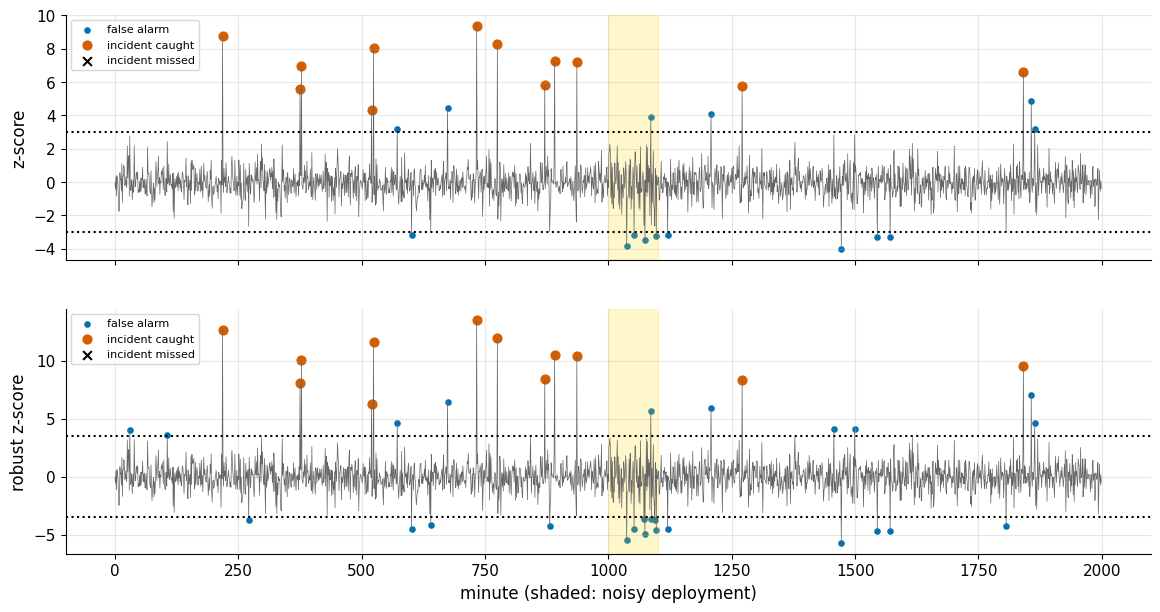

In [15]:
fig, axes = plt.subplots(2, 1, figsize=(14, 7), sharex=True); tm = np.arange(n1)
for ax, sc, thr, nm in [(axes[0], z1, 3, "z-score"), (axes[1], r1, 3.5, "robust z-score")]:
    ax.plot(tm, sc, color=NEUTRAL, linewidth=0.5); fl = np.abs(sc) > thr; ax.scatter(tm[fl & normal_min], sc[fl & normal_min], color=MAIN, s=14, label="false alarm"); ax.scatter(tm[isinc & fl], sc[isinc & fl], color=HIGHLIGHT, s=40, label="incident caught"); ax.scatter(tm[isinc & ~fl], sc[isinc & ~fl], color="black", marker="x", s=40, label="incident missed"); ax.axhline(thr, color="black", linestyle=":"); ax.axhline(-thr, color="black", linestyle=":"); ax.axvspan(1000, 1100, color="gold", alpha=0.2); ax.set_ylabel(nm); ax.legend(fontsize=8, loc="upper left")
axes[1].set_xlabel("minute (shaded: noisy deployment)"); plt.show()

### 12.5 Interpretation and decision (Example 1)
- All three rules catch **all 12 incidents**. The price is the false alarms on the 1,988 normal minutes: the z-score rule gives **15 (0.75 %)**, the robust z-score **26 (1.31 %)** and the IQR fences **75 (3.77 %)**, against the textbook 0.27 %. Even for pure $t_5$ noise a 3-sigma rule fires 1.17 % of the time (simulation over 2,000,000 points: 1.168 %, theory 1.172 %), and the noisy 100-minute deployment adds more. The robust rule is *not* the quietest: it estimates the spread of the central half of the data (11.6 ms, against 16.6 ms for the ordinary SD, inflated by the incidents and the deployment), so it is more sensitive and also flags more of the heavy-tail noise.
- **One wild reading changes everything for the z-score.** After a single logging error of 100,000 ms the SD becomes 2,234 ms and the z-score rule catches **0 of 12** incidents, while the robust rule still catches **12 of 12**.
- **Decision.** Use the median and MAD for the baseline of a monitored series (they cannot be broken by one bad reading) and then choose the threshold from the observed false-alarm rate on normal data rather than from the normal table; for heavy-tailed latencies a threshold of about 4 to 5 robust units is a better starting point than 3.5.

---
### Example 2: card-transaction fraud with the Mahalanobis distance

**Scenario.** 10,000 normal transactions have three correlated features: log-amount, hour of day (as a score) and distance from home (log-km); the covariance is known to the bank only through data. Forty fraudulent transactions are injected: amounts and distances that are *individually plausible* but break the correlation. We compare (a) the largest per-feature |z|, (b) the Euclidean distance of the z-scores, and (c) the Mahalanobis distance with the chi-square cut-off at $\alpha=0.001$.

**Questions.** (1) AUC of the three scores. (2) At the cut-off $\chi^2_{3,0.999}=16.27$: false-alarm rate, recall of the frauds and precision. (3) How would the precision change if fraud were rarer (1 in 10,000)?

In [16]:
g = np.random.default_rng(21); S3 = np.array([[1.0, 0.8, 0.7], [0.8, 1.0, 0.6], [0.7, 0.6, 1.0]]); mu3 = np.array([4.0, 12.0, 2.0]); sd3 = np.array([0.8, 4.0, 1.0]); Sn = S3 * np.outer(sd3, sd3); Xn3 = g.multivariate_normal(mu3, Sn, 10_000)
fr = mu3 + sd3 * g.normal(size=(40, 3)) * 0.8; fr[:, 0] += 1.6 * sd3[0]; fr[:, 2] -= 1.6 * sd3[2]; X_all = np.vstack([Xn3, fr]); y_all = np.r_[np.zeros(10_000), np.ones(40)].astype(int)
mu_h, S_h = Xn3.mean(axis=0), np.cov(Xn3.T); zmax = np.max(np.abs((X_all - mu_h) / Xn3.std(axis=0)), axis=1); eu = np.linalg.norm((X_all - mu_h) / Xn3.std(axis=0), axis=1); dm = d2(X_all, mu_h, S_h)
au = {"max per-feature |z|": auc(zmax, y_all), "Euclidean z-distance": auc(eu, y_all), "Mahalanobis D2": auc(dm, y_all)}; print("Q1: AUC", {k: round(v, 4) for k, v in au.items()})
cut = stats.chi2.ppf(0.999, 3); fl = dm > cut; tp = int((fl & (y_all == 1)).sum()); fp = int((fl & (y_all == 0)).sum()); print(f"Q2: cut-off {cut:.2f}: false alarm rate {fp / 10_000:.5f} (nominal 0.001), recall {tp / 40:.3f}, precision {tp / max(tp + fp, 1):.3f} ({tp} true, {fp} false alerts)")
for prev in (40 / 10_040, 1e-3, 1e-4): rec, far = tp / 40, fp / 10_000; print(f"Q3: prevalence {prev:.5f}: precision = recall*prev / (recall*prev + FAR*(1-prev)) = {rec * prev / (rec * prev + far * (1 - prev)):.4f}")

Q1: AUC {'max per-feature |z|': np.float64(0.8215), 'Euclidean z-distance': np.float64(0.8209), 'Mahalanobis D2': np.float64(0.9539)}
Q2: cut-off 16.27: false alarm rate 0.00080 (nominal 0.001), recall 0.650, precision 0.765 (26 true, 8 false alerts)
Q3: prevalence 0.00398: precision = recall*prev / (recall*prev + FAR*(1-prev)) = 0.7647
Q3: prevalence 0.00100: precision = recall*prev / (recall*prev + FAR*(1-prev)) = 0.4485
Q3: prevalence 0.00010: precision = recall*prev / (recall*prev + FAR*(1-prev)) = 0.0752


### 12.5 Asserts

In [17]:
assert au["Mahalanobis D2"] > au["Euclidean z-distance"] and au["Mahalanobis D2"] > au["max per-feature |z|"] and abs(fp / 10_000 - 0.001) < 0.0012 and tp / 40 > 0.6 and abs(cut - 16.2662) < 1e-3
print("all checks passed")

all checks passed


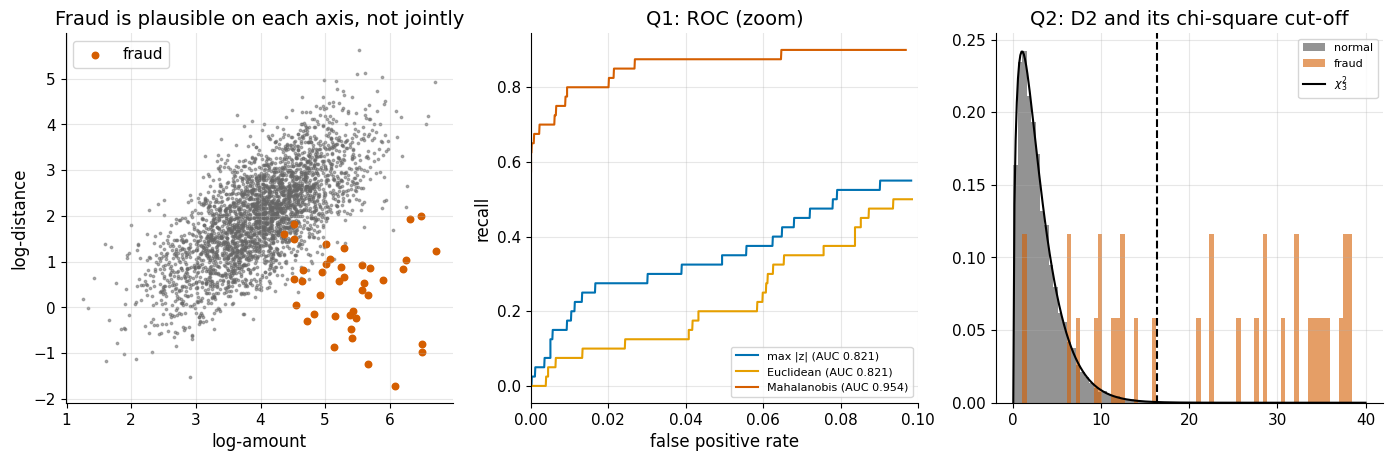

In [18]:
fig, axes = plt.subplots(1, 3, figsize=(17, 4.8)); axes[0].scatter(Xn3[:3000, 0], Xn3[:3000, 2], s=3, color=NEUTRAL, alpha=0.5); axes[0].scatter(fr[:, 0], fr[:, 2], s=22, color=HIGHLIGHT, label="fraud"); axes[0].set_xlabel("log-amount"); axes[0].set_ylabel("log-distance"); axes[0].legend(); axes[0].set_title("Fraud is plausible on each axis, not jointly")
for nm, sc, colr in [("max |z|", zmax, MAIN), ("Euclidean", eu, SIM), ("Mahalanobis", dm, HIGHLIGHT)]: thr = np.unique(np.quantile(sc, np.linspace(0.9, 1, 600))); axes[1].plot([np.mean(sc[y_all == 0] > t) for t in thr], [np.mean(sc[y_all == 1] > t) for t in thr], color=colr, label=f"{nm} (AUC {auc(sc, y_all):.3f})")
axes[1].set_xlim(0, 0.1); axes[1].legend(fontsize=8); axes[1].set_xlabel("false positive rate"); axes[1].set_ylabel("recall"); axes[1].set_title("Q1: ROC (zoom)")
axes[2].hist(dm[y_all == 0], bins=np.linspace(0, 40, 80), density=True, color=NEUTRAL, alpha=0.7, label="normal"); axes[2].hist(dm[y_all == 1], bins=np.linspace(0, 40, 80), density=True, color=HIGHLIGHT, alpha=0.6, label="fraud"); axes[2].plot(np.linspace(0, 40, 300), stats.chi2.pdf(np.linspace(0, 40, 300), 3), color="black", label="$\\chi^2_3$"); axes[2].axvline(cut, color="black", linestyle="--"); axes[2].legend(fontsize=8); axes[2].set_title("Q2: D2 and its chi-square cut-off")
plt.show()

### 12.7 Interpretation and decision (Example 2)
- The fraud is plausible on every axis but breaks the correlation structure: the AUC of the largest per-feature |z| is **0.822**, of the Euclidean z-distance **0.821** and of the Mahalanobis distance **0.954**.
- At the chi-square cut-off $\chi^2_{3,0.999}=16.27$ the false-alarm rate is **0.080 %** (8 of 10,000, about the nominal 0.1 %), the recall **65.0 %** (26 of 40 frauds) and the precision **76.5 %** (26 true and 8 false alerts).
- **The base rate matters.** With the same detector, precision falls to **44.9 %** if fraud is 1 in 1,000 transactions and to **7.5 %** if it is 1 in 10,000: with rare fraud most alerts are false, so alerts need a second, cheaper check before a human looks at them.
- **Decision.** Score with the Mahalanobis distance and set the cut-off from the false-alarm budget; evaluate with precision at the real prevalence, not with the AUC alone.

---
### Example 3: masking and the robust covariance

**Scenario.** The 2D cloud $N(0,[[4,3],[3,4]])$ (1,000 points) is contaminated by 200 outliers (17 %) clustered around $(7,-7)$ (across the correlation). We estimate the centre and covariance with the classical formulas and with the MCD, then compute the Mahalanobis distance of every point.

**Questions.** (1) How do the classical and robust estimates compare with the truth? (2) What share of the 200 outliers does each flag at the 99.9 % cut-off, and how many clean points are falsely flagged? (3) How does the classical estimate degrade as contamination grows from 0 to 40 %?

In [19]:
g = np.random.default_rng(31); Xcl = g.multivariate_normal([0, 0], C, 1000); out = g.multivariate_normal([7, -7], [[0.5, 0], [0, 0.5]], 200); Xc3 = np.vstack([Xcl, out]); yc = np.r_[np.zeros(1000), np.ones(200)].astype(int)
mu_cl, S_cl = Xc3.mean(axis=0), np.cov(Xc3.T); mu_rb, S_rb = mcd(Xc3, seed=2); cut2 = stats.chi2.ppf(0.999, 2)
print("Q1: true centre (0, 0), covariance [[4, 3], [3, 4]]"); print("classical:", mu_cl.round(2), S_cl.round(2).tolist()); print("robust (MCD):", mu_rb.round(2), S_rb.round(2).tolist())
for nm, m_, S_ in [("classical", mu_cl, S_cl), ("robust", mu_rb, S_rb)]: dd_ = d2(Xc3, m_, S_); fl = dd_ > cut2; print(f"Q2 {nm}: outliers flagged {np.sum(fl & (yc == 1))}/200, clean points flagged {np.sum(fl & (yc == 0))}/1000, AUC {auc(dd_, yc):.4f}")
rows = []
for frac in (0, 0.05, 0.1, 0.2, 0.3, 0.4):
    no = int(frac * 1000 / (1 - frac)); Xt = np.vstack([Xcl, g.multivariate_normal([7, -7], [[0.5, 0], [0, 0.5]], no)]) if no else Xcl; m1_, S1_ = Xt.mean(axis=0), np.cov(Xt.T); m2_, S2_ = mcd(Xt, seed=3); rows.append((frac, np.linalg.norm(m1_), np.linalg.norm(m2_), np.abs(S1_ - np.array(C)).max(), np.abs(S2_ - np.array(C)).max()))
print("Q3:"); print(pd.DataFrame(rows, columns=["contamination", "centre error classical", "centre error MCD", "covariance error classical", "covariance error MCD"]).round(3).to_string(index=False))

Q1: true centre (0, 0), covariance [[4, 3], [3, 4]]
classical: [ 1.17 -1.16] [[10.58, -4.05], [-4.05, 10.53]]
robust (MCD): [0.   0.03] [[4.71, 3.57], [3.57, 4.54]]
Q2 classical: outliers flagged 0/200, clean points flagged 0/1000, AUC 0.9431
Q2 robust: outliers flagged 200/200, clean points flagged 2/1000, AUC 1.0000


Q3:
 contamination  centre error classical  centre error MCD  covariance error classical  covariance error MCD
          0.00                   0.015             0.020                       0.479                 0.452
          0.05                   0.484             0.014                       2.618                 0.570
          0.10                   0.988             0.034                       4.627                 0.637
          0.20                   1.976             0.026                       8.196                 0.708
          0.30                   2.963             3.242                      10.964                13.617
          0.40                   3.958             4.476                      12.809                15.616


### 12.6 Asserts

In [20]:
dc_ = d2(Xc3, mu_cl, S_cl); dr_ = d2(Xc3, mu_rb, S_rb); assert np.sum((dr_ > cut2) & (yc == 1)) > 190 and np.sum((dc_ > cut2) & (yc == 1)) < np.sum((dr_ > cut2) & (yc == 1)) and np.linalg.norm(mu_rb) < 0.4 and np.linalg.norm(mu_cl) > 1.0 and rows[3][3] > 5 * rows[3][4] and rows[4][2] > 1.0 and rows[3][2] < 0.1
print("all checks passed")

all checks passed


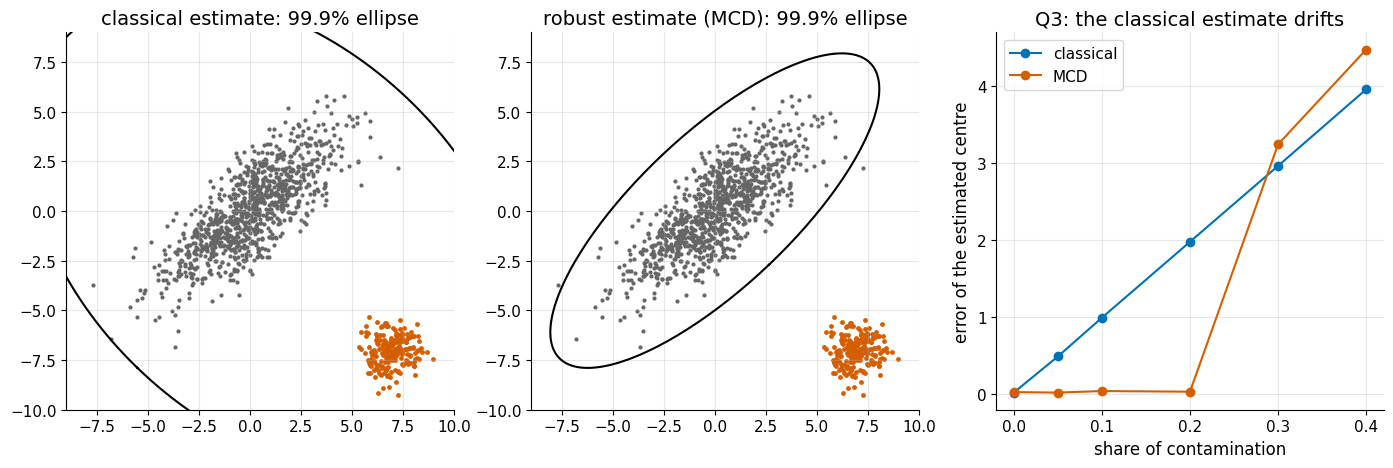

In [21]:
fig, axes = plt.subplots(1, 3, figsize=(17, 4.9)); ang = np.linspace(0, 2 * np.pi, 200)
for ax, (nm, m_, S_) in zip(axes[:2], [("classical estimate", mu_cl, S_cl), ("robust estimate (MCD)", mu_rb, S_rb)]):
    w, v = np.linalg.eigh(S_); e = (v @ (np.sqrt(w)[:, None] * np.sqrt(cut2) * np.array([np.cos(ang), np.sin(ang)]))).T + m_; ax.scatter(Xcl[:, 0], Xcl[:, 1], s=4, color=NEUTRAL); ax.scatter(out[:, 0], out[:, 1], s=6, color=HIGHLIGHT); ax.plot(e[:, 0], e[:, 1], color="black"); ax.set_xlim(-9, 10); ax.set_ylim(-10, 9); ax.set_title(f"{nm}: 99.9% ellipse")
fr_ = np.array([r[0] for r in rows]); axes[2].plot(fr_, [r[1] for r in rows], "o-", color=MAIN, label="classical"); axes[2].plot(fr_, [r[2] for r in rows], "o-", color=HIGHLIGHT, label="MCD"); axes[2].set_xlabel("share of contamination"); axes[2].set_ylabel("error of the estimated centre"); axes[2].legend(); axes[2].set_title("Q3: the classical estimate drifts")
plt.show()

### 12.9 Interpretation and decision (Example 3)
- **Masking is complete here.** The 200 outliers (17 %) drag the classical centre to (1.17, -1.16) and inflate the covariance to $\begin{pmatrix}10.6&-4.1\-4.1&10.5\end{pmatrix}$ (true $\begin{pmatrix}4&3\3&4\end{pmatrix}$, and with the wrong sign of the correlation): the classical rule flags **0 of 200 outliers** (AUC 0.943), because they have inflated their own yardstick.
- The robust (reweighted MCD) estimate recovers the centre (0.00, 0.03) and the covariance $\begin{pmatrix}4.7&3.6\3.6&4.5\end{pmatrix}$; it flags **200 of 200 outliers** and 2 of 1,000 clean points (AUC 1.000).
- As the contamination grows the classical centre error rises linearly (0.48, 0.99, 1.98 at 5 %, 10 %, 20 %) while the MCD stays below 0.04. **Beyond the breakdown point the robust estimate fails too:** with $h=75\%$ it breaks between 20 % and 30 % contamination (centre error 3.2 at 30 % and 4.5 at 40 %, worse than the classical one).
- **Decision.** Estimate "normal" robustly (MCD or trimming) and always check how much of the data was discarded; if you suspect more than about 25 % anomalies, the model of "normal" itself needs revisiting.

---
### Example 4: monitoring 500 metrics without drowning in alerts

**Scenario.** A dashboard tracks 500 independent metrics, each normal with its own mean and SD, once per day. On a given day 5 metrics have really shifted by 4 standard deviations. Compare the plain 3-sigma rule, a Bonferroni rule ($\alpha=0.05/500$) and Benjamini-Hochberg at $q=0.05$.

**Questions.** (1) How many alerts and false alarms per day for each rule (average over 2,000 days), and how often is a real shift detected? (2) What is the probability that a day has at least one false alarm?

In [22]:
g = np.random.default_rng(41); m = 500; days = 2000; shift = np.zeros(m); shift[:5] = 4.0; res = {k: {"alerts": [], "false": [], "found": []} for k in ("3-sigma", "Bonferroni", "Benjamini-Hochberg")}
for _ in range(days):
    z = g.normal(size=m) + shift; pv = 2 * stats.norm.sf(np.abs(z)); flags = {"3-sigma": np.abs(z) > 3, "Bonferroni": pv < 0.05 / m}; o = np.argsort(pv); ok = np.where(pv[o] <= 0.05 * np.arange(1, m + 1) / m)[0]; bh = np.zeros(m, bool)
    if len(ok): bh[o[:ok.max() + 1]] = True
    flags["Benjamini-Hochberg"] = bh
    for k, fl in flags.items(): res[k]["alerts"].append(fl.sum()); res[k]["false"].append(fl[5:].sum()); res[k]["found"].append(fl[:5].sum())
tb4 = pd.DataFrame({k: {"alerts per day": np.mean(v["alerts"]), "false alarms per day": np.mean(v["false"]), "P(any false alarm)": np.mean(np.array(v["false"]) > 0), "real shifts found (of 5)": np.mean(v["found"])} for k, v in res.items()}).T; print(tb4.round(4).to_string()); print("theory: false alarms per day with 3 sigma", round(495 * 2 * stats.norm.sf(3), 3), "| P(any)", round(1 - (1 - 2 * stats.norm.sf(3)) ** 495, 4), "| power of one 4-sigma shift at 3 sigma:", round(float(stats.norm.sf(3 - 4) + stats.norm.cdf(-3 - 4)), 4))

                    alerts per day  false alarms per day  P(any false alarm)  real shifts found (of 5)
3-sigma                     5.5570                1.3420              0.7465                     4.215
Bonferroni                  2.7715                0.0485              0.0480                     2.723
Benjamini-Hochberg          3.6095                0.2465              0.2095                     3.363
theory: false alarms per day with 3 sigma 1.336 | P(any) 0.7377 | power of one 4-sigma shift at 3 sigma: 0.8413


### 12.7 Asserts

In [23]:
assert abs(tb4.loc["3-sigma", "false alarms per day"] - 495 * 2 * stats.norm.sf(3)) < 0.1 and tb4.loc["Bonferroni", "false alarms per day"] < 0.1 and tb4.loc["Benjamini-Hochberg", "real shifts found (of 5)"] >= tb4.loc["Bonferroni", "real shifts found (of 5)"] - 1e-9 and tb4.loc["3-sigma", "P(any false alarm)"] > 0.7
print("all checks passed")

all checks passed


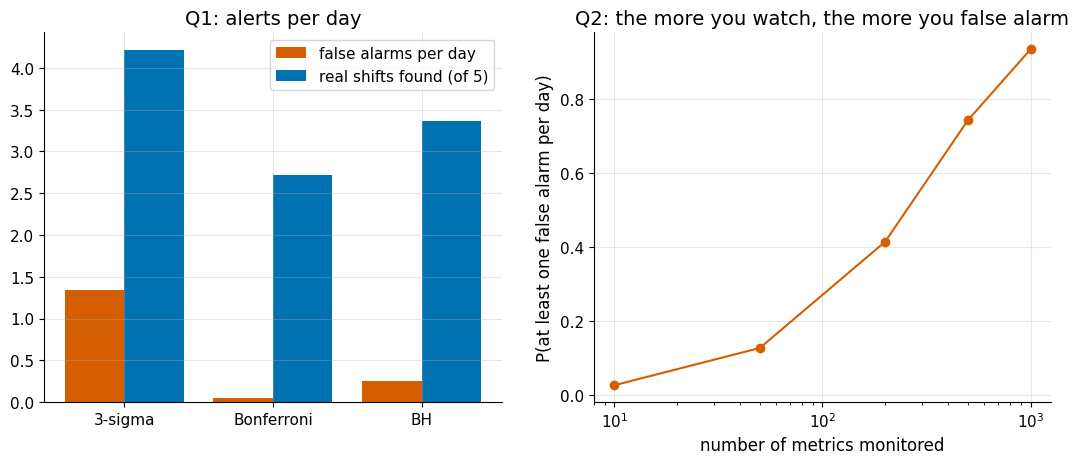

In [24]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.8)); x_ = np.arange(3); axes[0].bar(x_ - 0.2, tb4["false alarms per day"], 0.4, color=HIGHLIGHT, label="false alarms per day"); axes[0].bar(x_ + 0.2, tb4["real shifts found (of 5)"], 0.4, color=MAIN, label="real shifts found (of 5)"); axes[0].set_xticks(x_); axes[0].set_xticklabels(["3-sigma", "Bonferroni", "BH"]); axes[0].legend(); axes[0].set_title("Q1: alerts per day")
axes[1].plot(tb.set_index("metrics").index, tb["P(at least one) sim"], "o-", color=HIGHLIGHT); axes[1].set_xscale("log"); axes[1].set_xlabel("number of metrics monitored"); axes[1].set_ylabel("P(at least one false alarm per day)"); axes[1].set_title("Q2: the more you watch, the more you false alarm")
plt.show()

### 12.11 Interpretation and decision (Example 4)
- The plain 3-sigma rule gives **5.56 alerts per day**: 4.2 of the 5 real shifts (theory: power 0.841 for a 4-sigma shift) and **1.34 false alarms**, so **74.7 %** of days contain at least one false alarm (theory 73.8 % for 495 null metrics).
- **Bonferroni** ($\alpha=0.05/500$) cuts the false alarms to **0.05 per day** (a day with any false alarm 4.8 %) but also finds only 2.72 of the 5 shifts. **Benjamini-Hochberg** (FDR 5 %) is in between: 3.61 alerts, **0.25 false alarms per day** and 3.36 shifts found.
- **Decision.** For a large dashboard control the false discovery rate (Benjamini-Hochberg) rather than the per-metric rate; it keeps most of the power while the daily alert list stays short enough to read.

## 13. Where it is used

### Statistics
- **Outlier tests and robust statistics** (MAD, Tukey fences, MCD and M-estimators), **control charts** in quality engineering, **multivariate process monitoring** (Hotelling's $T^2$ is the Mahalanobis distance of a mean), data cleaning before a regression.

### Data science
- **Fraud and intrusion detection, system and KPI monitoring, data validation and drift alerts**, quality control, rule-based alerting with a false-alarm budget, **dashboards with hundreds of metrics** (multiple-testing control).

### ML and AI
- **Out-of-distribution detection** (Mahalanobis distance on network embeddings), **novelty detection** with Gaussian and mixture density models (09_04), autoencoder reconstruction error, isolation forests and one-class models, and monitoring of model inputs and predictions in production.

## 14. Common pitfalls and misconceptions

- **Using the mean and SD on contaminated data:** one huge reading ruins the z-score (Example 1); use the median and MAD.
- **Quoting 0.27 % for any 3-sigma rule:** true only for normal data; heavy tails make it 3 % or more (Example 1).
- **Using Euclidean distance on correlated features** (Example 2) or **the 2D cut-off in 10 dimensions** (9.3).
- **Masking:** estimating the covariance on data that include the anomalies hides them (Example 3); use a robust estimate or iterate with trimming.
- **Ignoring the base rate:** a 0.1 % false-alarm rate on rare anomalies still gives mostly false alerts (Example 2, Q3).
- **Alerting on every metric at 3 sigma:** hundreds of metrics produce alerts every day (Example 4); control the false discovery rate.
- **Treating "anomalous" as "bad":** the detector flags *unusual*; a human or a labelled evaluation decides what matters.

## 15. Exercises

1. Compute $P(|Z|>c)$ for $c=2,3,4$ and the expected number of false alarms in 1 year of daily data for each.
2. The data $(10,11,9,10,12,10,11,95)$ contain an outlier. Compute the z-score and the robust z-score of 95.
3. For $N(0,[[1,0.9],[0.9,1]])$ compute $D^2$ for the points $(1,1)$ and $(1,-1)$ and compare with their Euclidean norms.
4. Find the 99 % and 99.9 % chi-square cut-offs for $p=4$ and the false-alarm rate of the 99.9 % cut-off of $p=2$ when used in $p=4$.
5. With 120 independent metrics and a 3-sigma rule, what is the probability of no false alarm in a day, and in a 30-day month?
6. (Harder) Implement a one-step Hotelling $T^2$ test for a shift in the mean of a 3-feature process and find its power for a shift of one standard deviation in the first feature with $n=20$ points per day.

Solutions are at the end.

## 16. Summary table

| Method | Formula | Strength | Weakness |
|---|---|---|---|
| z-score | $(x-\bar x)/s$ | simple | masked by outliers, normal tails |
| Robust z | $0.6745(x-\mathrm{med})/\mathrm{MAD}$ | 50 % breakdown | one variable |
| IQR fences | $Q\pm1.5\,\mathrm{IQR}$ | no scale model | skewed data |
| Mahalanobis | $(x-\mu)^\top\Sigma^{-1}(x-\mu)\sim\chi^2_p$ | correlation-aware, calibrated | needs Gaussian, masking |
| MCD | covariance of the best $h$ points | robust | slower, $h$ choice |
| Density score | $-\ln\hat f$ | non-Gaussian | needs more data |
| Many metrics | Bonferroni, BH | controlled false alarms | lower power |
| tools | `chi2.ppf`, `median_abs_deviation`, `mahalanobis` | | |

## Solutions

In [25]:
print("1:", {c: (round(2 * stats.norm.sf(c), 6), round(365 * 2 * stats.norm.sf(c), 2)) for c in (2, 3, 4)}, "(probability, alarms per year)")
v = np.array([10, 11, 9, 10, 12, 10, 11, 95.0]); print(f"2: z-score of 95: {zs(v)[-1]:.3f} (the outlier inflates the SD), robust z: {rz(v)[-1]:.1f}")
Sx = np.array([[1, 0.9], [0.9, 1]]); print("3: D2(1,1) =", d2(np.array([[1.0, 1.0]]), np.zeros(2), Sx).round(3), "(Euclidean norm^2 = 2) | D2(1,-1) =", d2(np.array([[1.0, -1.0]]), np.zeros(2), Sx).round(3), "(Euclidean norm^2 = 2)")
print(f"4: chi2(4): 99% {stats.chi2.ppf(0.99, 4):.3f}, 99.9% {stats.chi2.ppf(0.999, 4):.3f} | false-alarm rate of the p = 2 cut-off in p = 4: {stats.chi2.sf(stats.chi2.ppf(0.999, 2), 4):.4f}")
q = 2 * stats.norm.sf(3); print(f"5: P(no false alarm) in a day {(1 - q) ** 120:.4f}, in 30 days {(1 - q) ** (120 * 30):.4f}")
g = np.random.default_rng(51); mu0 = np.zeros(3); S0 = np.eye(3); nn = 20; crit = stats.f.ppf(0.99, 3, nn - 3) * 3 * (nn - 1) / (nn - 3); hit = 0; R = 4000
for _ in range(R): Xd = g.multivariate_normal([1.0, 0, 0], S0, nn); mb = Xd.mean(axis=0); Sb = np.cov(Xd.T); T2 = nn * mb @ np.linalg.solve(Sb, mb); hit += T2 > crit
print(f"6: Hotelling T2 critical value (1% level, n = 20, p = 3) {crit:.2f}; power against a 1 SD shift in the first feature: {hit / R:.3f}")
assert abs(d2(np.array([[1.0, -1.0]]), np.zeros(2), Sx)[0] - 20) < 1e-9 and abs(rz(v)[-1]) > 20 and zs(v)[-1] < 2.7

1: {2: (np.float64(0.0455), np.float64(16.61)), 3: (np.float64(0.0027), np.float64(0.99)), 4: (np.float64(6.3e-05), np.float64(0.02))} (probability, alarms per year)
2: z-score of 95: 2.474 (the outlier inflates the SD), robust z: 114.0
3: D2(1,1) = [1.053] (Euclidean norm^2 = 2) | D2(1,-1) = [20.] (Euclidean norm^2 = 2)
4: chi2(4): 99% 13.277, 99.9% 18.467 | false-alarm rate of the p = 2 cut-off in p = 4: 0.0079
5: P(no false alarm) in a day 0.7230, in 30 days 0.0001


6: Hotelling T2 critical value (1% level, n = 20, p = 3) 17.38; power against a 1 SD shift in the first feature: 0.758


**1.** $P(|Z|>c)=$ **0.0455, 0.0027 and 0.000063** for $c=2,3,4$, i.e. about **16.6, 0.99 and 0.02 false alarms per year** of daily data.

**2.** The z-score of 95 is only **2.47** (the outlier inflates the standard deviation and the mean), while the robust z-score is **114**.

**3.** $D^2(1,1)=0.2/0.19=$ **1.05** and $D^2(1,-1)=3.8/0.19=$ **20.0**, although both points have squared Euclidean norm 2: the second one breaks the correlation of 0.9 and is beyond the 99.9 % cut-off for $p=2$ (13.8).

**4.** For $p=4$ the 99 % and 99.9 % cut-offs are **13.28** and **18.47**; using the $p=2$ cut-off (13.82) in 4 dimensions gives a false-alarm rate of **0.79 %** instead of 0.1 %.

**5.** $P(\text{no false alarm})=0.9973^{120}=$ **0.723** in a day and $0.723^{30}\approx$ **0.0001** over a 30-day month: with 120 metrics a month without a single false alarm is almost impossible.

**6.** The 1 % critical value of Hotelling's $T^2$ for $n=20$, $p=3$ is **17.38**; against a shift of 1 SD in the first feature the power is **0.758**.